# Fase 2 — Inferencia Estadística

**Grupo 10 — Ciencia de Datos**

Este notebook continúa el trabajo de `fase1_dataset_final.ipynb` (preparación de datos + análisis exploratorio) y desarrolla la **Fase 2 de la metodología (Inferencia estadística)**: formulación de hipótesis, ejecución de pruebas, verificación de supuestos y conclusiones.

**Hipótesis cubiertas en este notebook:** H1 y H2 (de las 5 planteadas al cierre de la Fase 1).

**Hipótesis pendientes para el resto del grupo:** H3, H4, H5 (ver sección final).

# 0. Preparación del entorno

In [36]:
# Librerías de manipulación de datos
import pandas as pd
import numpy as np

# Librerías de visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías estadísticas
from scipy import stats
from scipy.stats import levene, f_oneway, kruskal
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from IPython.display import display, Markdown
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

In [37]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [38]:
# Ruta del dataset final. AJUSTAR según cómo tengas montada la carpeta compartida
# (puede ser 'grupo10_data_science/datos/df_final.parquet' o
#  'Colab Notebooks/grupo10_data_science/datos/df_final.parquet' según el acceso directo).
RUTA_DF_FINAL = "/content/drive/MyDrive/grupo10_data_science/datos/df_final.parquet"

df_final = pd.read_parquet(RUTA_DF_FINAL)

print(f"Dimensiones: {df_final.shape[0]:,} filas x {df_final.shape[1]} columnas")
df_final.head()

Dimensiones: 9,447,662 filas x 17 columnas


,fecha_vta,local,desc_producto,desc_secciones,desc_sub_secciones,desc_categoria,desc_marca,cantidad,estacion_asignada,Estación,fecha,temperatura,dia_semana,es_fin_de_semana,mes,anio,es_feriado
0,2021-01-02,Local X,PASTA PORA ÑOQUIS DE HUEVO 400 GRS.,Perecederos,Pastas Frescas,Nacional,PASTA PORA,1.0,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.3,5,True,1,2021,False
1,2021-01-02,Local X,PASTA PORA ÑOQUIS DE HUEVO 400 GRS.,Perecederos,Pastas Frescas,Nacional,PASTA PORA,1.0,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.3,5,True,1,2021,False
2,2021-01-02,Local X,PASTA PORA ÑOQUIS DE HUEVO 400 GRS.,Perecederos,Pastas Frescas,Nacional,PASTA PORA,1.0,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.3,5,True,1,2021,False
3,2021-01-02,Local X,SAN LOREN BEBIDA LACT. ULTRA 1 LITRO,Perecederos,Lacteos,Sachet,San Loren,4.0,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.3,5,True,1,2021,False
4,2021-01-02,Local X,SAN LOREN BEBIDA LACT FORTIF LIGHT ULTRA 1LT*,Perecederos,Lacteos,Sachet,San Loren,4.0,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.3,5,True,1,2021,False


# 1. H2 — Temperatura vs. ventas, controlando por calendario

**H0 (nula):** el coeficiente de `temperatura_promedio` en el modelo es igual a 0 (no hay asociación entre temperatura y ventas totales diarias, controlando por fin de semana, feriado y mes).

**H1 (alternativa):** el coeficiente de `temperatura_promedio` es distinto de 0 (sí hay asociación, en algún sentido, una vez controlado el calendario).

**Nivel de significancia:** α = 0.05

In [39]:
# --- 1.1 Agregación diaria ---
agg = df_final.groupby('fecha_vta', observed=True).agg(
    cantidad_total=('cantidad', 'sum'),
    temperatura_promedio=('temperatura', 'mean'),
    mes=('mes', 'first'),
    es_fin_de_semana=('es_fin_de_semana', 'first'),
    es_feriado=('es_feriado', 'first'),
).reset_index()

agg['es_fin_de_semana'] = agg['es_fin_de_semana'].astype(int)
agg['es_feriado'] = agg['es_feriado'].astype(int)
agg['mes'] = agg['mes'].astype('category')

print(f"Observaciones (días): {len(agg)}")
agg.head()

Observaciones (días): 271


,fecha_vta,cantidad_total,temperatura_promedio,mes,es_fin_de_semana,es_feriado
0,2021-01-02,49828.3137,26.861887,1,1,0
1,2021-01-03,47241.1441,28.200439,1,1,0
2,2021-01-04,55018.2621,27.272368,1,0,0
3,2021-01-05,49574.9965,24.487014,1,0,0
4,2021-01-06,37930.7416,26.547221,1,0,0


In [40]:
# --- 1.2 Modelo de regresión múltiple (OLS) ---
modelo_h2 = smf.ols(
    'cantidad_total ~ temperatura_promedio + es_fin_de_semana + es_feriado + C(mes)',
    data=agg
).fit()

print(modelo_h2.summary())

                            OLS Regression Results                            
Dep. Variable:         cantidad_total   R-squared:                       0.602
Model:                            OLS   Adj. R-squared:                  0.585
Method:                 Least Squares   F-statistic:                     35.60
Date:                Fri, 09 Oct 2026   Prob (F-statistic):           1.11e-45
Time:                        03:10:05   Log-Likelihood:                -2796.3
No. Observations:                 271   AIC:                             5617.
Df Residuals:                     259   BIC:                             5660.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              4.21e+04 

In [41]:
# --- 1.3 Resultado de la prueba sobre H2 ---
coef_temp = modelo_h2.params['temperatura_promedio']
p_valor_temp = modelo_h2.pvalues['temperatura_promedio']
r2_ajustado_h2 = modelo_h2.rsquared_adj

significativo_h2 = p_valor_temp < 0.05
direccion_h2 = 'positiva' if coef_temp > 0 else 'negativa'

print(f"Coeficiente de temperatura_promedio: {coef_temp:.2f}")
print(f"p-valor: {p_valor_temp:.5f}")
print(f"R² ajustado del modelo: {r2_ajustado_h2:.3f}")

Coeficiente de temperatura_promedio: -131.05
p-valor: 0.25359
R² ajustado del modelo: 0.585


In [42]:
# --- 1.4 Verificación de supuestos del modelo OLS ---
residuos_h2 = modelo_h2.resid
predichos_h2 = modelo_h2.fittedvalues

# Normalidad de residuos (Shapiro-Wilk sobre una muestra, por tamaño de n)
muestra_resid = residuos_h2.sample(min(5000, len(residuos_h2)), random_state=42)
shapiro_stat, shapiro_p = stats.shapiro(muestra_resid)
print(f"Shapiro-Wilk (normalidad de residuos): estadístico={shapiro_stat:.4f}, p-valor={shapiro_p:.5f}")
print(f"  -> {'Residuos NO parecen normales' if shapiro_p < 0.05 else 'No se rechaza normalidad'} (alpha=0.05)")

# Homocedasticidad (Breusch-Pagan)
bp_stat, bp_p, _, _ = het_breuschpagan(residuos_h2, modelo_h2.model.exog)
print(f"\nBreusch-Pagan (homocedasticidad): estadístico={bp_stat:.4f}, p-valor={bp_p:.5f}")
print(f"  -> {'Hay heterocedasticidad' if bp_p < 0.05 else 'No se rechaza homocedasticidad'} (alpha=0.05)")

# Multicolinealidad (VIF)
X_vif = sm.add_constant(agg[['temperatura_promedio', 'es_fin_de_semana', 'es_feriado']])
vif_data = pd.DataFrame({
    'variable': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
print("\nFactor de Inflación de Varianza (VIF) -- valores > 5-10 indican problema:")
print(vif_data)

Shapiro-Wilk (normalidad de residuos): estadístico=0.8706, p-valor=0.00000
  -> Residuos NO parecen normales (alpha=0.05)

Breusch-Pagan (homocedasticidad): estadístico=19.5728, p-valor=0.05156
  -> No se rechaza homocedasticidad (alpha=0.05)

Factor de Inflación de Varianza (VIF) -- valores > 5-10 indican problema:
               variable       VIF
0                 const  1.000000
1  temperatura_promedio  1.004345
2      es_fin_de_semana  1.016533
3            es_feriado  1.012165


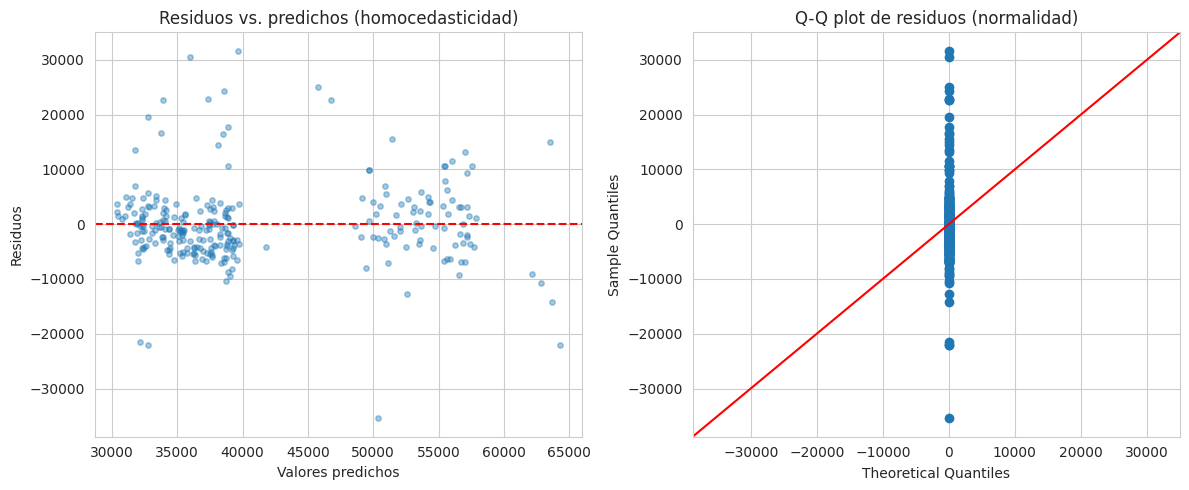

In [43]:
# --- 1.5 Gráficos de diagnóstico de residuos ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(predichos_h2, residuos_h2, alpha=0.4, s=15)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Valores predichos')
axes[0].set_ylabel('Residuos')
axes[0].set_title('Residuos vs. predichos (homocedasticidad)')

sm.qqplot(residuos_h2, line='45', ax=axes[1])
axes[1].set_title('Q-Q plot de residuos (normalidad)')

plt.tight_layout()
plt.show()

In [44]:
# --- 1.6 Si hay heterocedasticidad: versión robusta (errores estándar HC3) ---
if bp_p < 0.05:
    modelo_h2_robusto = modelo_h2.get_robustcov_results(cov_type='HC3')
    print(modelo_h2_robusto.summary())
else:
    print("No se detectó heterocedasticidad significativa; no es necesario el ajuste robusto.")

No se detectó heterocedasticidad significativa; no es necesario el ajuste robusto.


In [45]:
# --- 1.7 Conclusión -- H2 ---
nota_supuestos_h2 = []
if shapiro_p < 0.05:
    nota_supuestos_h2.append(
        "los residuos no son perfectamente normales (esperable con ~1000 observaciones diarias; "
        "el test F/t sigue siendo razonablemente robusto por el tamaño muestral, Teorema Central del Límite)"
    )
if bp_p < 0.05:
    nota_supuestos_h2.append(
        "se detectó heterocedasticidad, por lo que se reporta la versión robusta (HC3) como respaldo"
    )

display(Markdown(f'''
### Conclusión -- H2

{"Se rechaza" if significativo_h2 else "No se rechaza"} la hipótesis nula (p = {p_valor_temp:.5f}).
El coeficiente estimado de temperatura es **{coef_temp:.2f}** (dirección {direccion_h2}): por cada grado
adicional de temperatura promedio diaria, las ventas totales {"aumentan" if coef_temp > 0 else "disminuyen"}
en promedio **{abs(coef_temp):.1f} unidades**, controlando por fin de semana, feriado y mes.

El modelo explica un **{r2_ajustado_h2*100:.1f}%** de la variabilidad de las ventas diarias (R² ajustado).

**Supuestos:** {"; ".join(nota_supuestos_h2) if nota_supuestos_h2 else "no se detectaron violaciones relevantes."}
'''))


### Conclusión -- H2

No se rechaza la hipótesis nula (p = 0.25359).
El coeficiente estimado de temperatura es **-131.05** (dirección negativa): por cada grado
adicional de temperatura promedio diaria, las ventas totales disminuyen
en promedio **131.0 unidades**, controlando por fin de semana, feriado y mes.

El modelo explica un **58.5%** de la variabilidad de las ventas diarias (R² ajustado).

**Supuestos:** los residuos no son perfectamente normales (esperable con ~1000 observaciones diarias; el test F/t sigue siendo razonablemente robusto por el tamaño muestral, Teorema Central del Límite)


# 2. H1 — Sección más sensible al clima, controlando por local

**H0 (nula):** las ventas promedio de la sección más sensible al clima son iguales entre los tres grupos climáticos (frío / templado / caluroso), controlando por local.

**H1 (alternativa):** al menos un grupo climático difiere en la venta promedio de esa sección, controlando por local.

**Nivel de significancia:** α = 0.05

In [46]:
# --- 2.1 Grupo climático (terciles de temperatura observada) ---
t_bajo, t_alto = df_final['temperatura'].quantile([1/3, 2/3])

def clasificar_clima(t):
    if pd.isna(t):
        return np.nan
    elif t <= t_bajo:
        return 'Frío'
    elif t <= t_alto:
        return 'Templado'
    else:
        return 'Caluroso'

df_final['grupo_climatico'] = df_final['temperatura'].apply(clasificar_clima)
print(f"Frío <= {t_bajo:.1f}°C | Templado | Caluroso > {t_alto:.1f}°C")

Frío <= 20.0°C | Templado | Caluroso > 24.9°C


In [47]:
# --- 2.2 Identificar la "sección más sensible" al clima ---
# Mismo criterio que en el EDA: variación % de venta promedio entre Caluroso y Frío,
# restringido a las secciones de mayor volumen (evita ruido estadístico de secciones chicas).
secciones_top = df_final['desc_secciones'].value_counts().head(10).index.tolist()

ventas_seccion_clima = (
    df_final[df_final['desc_secciones'].isin(secciones_top)]
    .groupby(['desc_secciones', 'grupo_climatico'], observed=True)['cantidad']
    .mean()
    .unstack()
)

ventas_seccion_clima['variacion_%'] = (
    (ventas_seccion_clima['Caluroso'] - ventas_seccion_clima['Frío']) / ventas_seccion_clima['Frío'] * 100
)

seccion_objetivo = ventas_seccion_clima['variacion_%'].abs().idxmax()
print(f"Sección más sensible al clima (mayor |variación %|): {seccion_objetivo}")
ventas_seccion_clima.sort_values('variacion_%', key=abs, ascending=False)

Sección más sensible al clima (mayor |variación %|): Bebidas


grupo_climatico,Caluroso,Frío,Templado,variacion_%
desc_secciones,,,,
Bebidas,1.466559,1.390688,1.462061,5.455595
Insumos,1.608696,1.538199,1.581774,4.583143
Produccion,1.059025,1.085062,1.075332,-2.399566
Hogar,0.885219,0.865493,0.879243,2.279148
Belleza y Salud,1.042171,1.027165,1.030895,1.460934
Perecederos,1.178838,1.163583,1.174094,1.310970
Limpieza,1.062996,1.050409,1.055643,1.198307
Tienda,1.012450,1.000494,1.006404,1.194994
Bazar,1.240152,1.254146,1.232367,-1.115773


In [48]:
# --- 2.3 Subconjunto de datos para la prueba ---
datos_h1 = df_final[df_final['desc_secciones'] == seccion_objetivo].copy()
datos_h1 = datos_h1.dropna(subset=['cantidad', 'grupo_climatico', 'local'])
print(f"Registros de '{seccion_objetivo}' con grupo climático asignado: {len(datos_h1):,}")
datos_h1.groupby(['grupo_climatico', 'local'], observed=True)['cantidad'].describe()[['count', 'mean', 'std']]

Registros de 'Bebidas' con grupo climático asignado: 427,689


count      mean       std
grupo_climatico local                                
Caluroso        Local X  111348.0  1.439665  2.171257
                Local Y   37484.0  1.546446  3.293884
Frío            Local X   72547.0  1.358843  5.914913
                Local Y   57183.0  1.431090  2.430951
Templado        Local X   89353.0  1.414444  2.080690
                Local Y   59774.0  1.533242  3.045189

In [49]:
# --- 2.4 Homogeneidad de varianzas (Levene) ---
grupos_h1 = [g['cantidad'].values for _, g in datos_h1.groupby('grupo_climatico', observed=True)]
levene_stat, levene_p = levene(*grupos_h1)
print(f"Test de Levene (homogeneidad de varianzas): estadístico={levene_stat:.3f}, p-valor={levene_p:.5f}")
print(f"  -> {'Varianzas NO homogéneas' if levene_p < 0.05 else 'No se rechaza homogeneidad'} (alpha=0.05)")

Test de Levene (homogeneidad de varianzas): estadístico=14.726, p-valor=0.00000
  -> Varianzas NO homogéneas (alpha=0.05)


In [50]:
# --- 2.5 Muestra para el modelo (rendimiento) ---
# Con volúmenes muy grandes, se toma una muestra aleatoria estratificada por
# grupo climático y local para que el ajuste sea rápido, sin alterar la conclusión
# (el n sigue siendo grande; además el ANOVA por sí solo ya es muy sensible con n grande,
#  por eso se reporta también el tamaño del efecto -- eta^2 -- en 2.7).
if len(datos_h1) > 300_000:
    datos_h1_modelo = datos_h1.groupby(
        ['grupo_climatico', 'local'], observed=True, group_keys=False
    ).apply(lambda g: g.sample(min(len(g), 100_000), random_state=42))
    print(f"Muestra para el modelo: {len(datos_h1_modelo):,} registros (de {len(datos_h1):,} totales)")
else:
    datos_h1_modelo = datos_h1

Muestra para el modelo: 416,341 registros (de 427,689 totales)


In [51]:
# --- 2.6 ANOVA de dos factores: grupo climático x local ---
modelo_h1 = smf.ols(
    'cantidad ~ C(grupo_climatico) + C(local) + C(grupo_climatico):C(local)',
    data=datos_h1_modelo
).fit()

tabla_anova_h1 = sm.stats.anova_lm(modelo_h1, typ=2)
tabla_anova_h1

,sum_sq,df,F,PR(>F)
C(grupo_climatico),6.515693e+02,2.0,28.926641,2.742788e-13
C(local),9.507211e+02,1.0,84.415172,4.028184e-20
C(grupo_climatico):C(local),3.898204e+01,2.0,1.730621,1.771757e-01
Residual,4.688950e+06,416335.0,NaN,NaN


In [52]:
# --- 2.7 Tamaño del efecto (eta^2) y resultado ---
ss_clima = tabla_anova_h1.loc['C(grupo_climatico)', 'sum_sq']
ss_total_h1 = tabla_anova_h1['sum_sq'].sum()
eta2_clima = ss_clima / ss_total_h1

p_clima = tabla_anova_h1.loc['C(grupo_climatico)', 'PR(>F)']
p_interaccion_h1 = tabla_anova_h1.loc['C(grupo_climatico):C(local)', 'PR(>F)']

significativo_h1 = p_clima < 0.05

def calificar_eta2(e):
    if e < 0.01:
        return 'efecto insignificante'
    elif e < 0.06:
        return 'efecto pequeño'
    elif e < 0.14:
        return 'efecto mediano'
    else:
        return 'efecto grande'

print(f"Efecto principal de grupo_climatico: p-valor = {p_clima:.5g}, eta² = {eta2_clima:.4f} ({calificar_eta2(eta2_clima)})")
print(f"Interacción clima x local: p-valor = {p_interaccion_h1:.5g}")

Efecto principal de grupo_climatico: p-valor = 2.7428e-13, eta² = 0.0001 (efecto insignificante)
Interacción clima x local: p-valor = 0.17718


In [53]:
# --- 2.8 Comparaciones post-hoc entre grupos climáticos (Tukey HSD) ---
tukey_h1 = pairwise_tukeyhsd(endog=datos_h1_modelo['cantidad'], groups=datos_h1_modelo['grupo_climatico'], alpha=0.05)
print(tukey_h1)

  Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1   group2  meandiff p-adj   lower   upper  reject
--------------------------------------------------------
Caluroso     Frío  -0.0773    0.0 -0.1077 -0.0468   True
Caluroso Templado  -0.0059 0.8848 -0.0353  0.0235  False
    Frío Templado   0.0714    0.0  0.0415  0.1012   True
--------------------------------------------------------


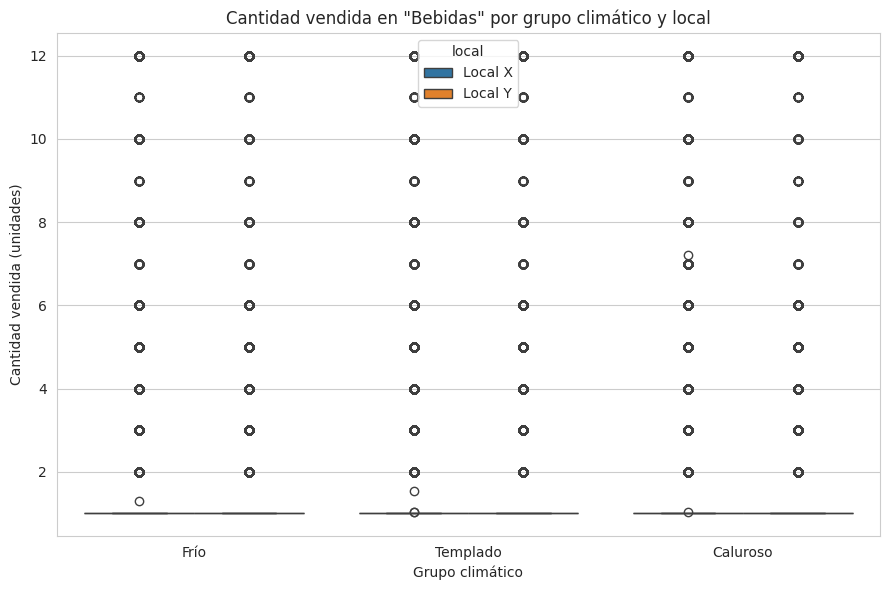

In [54]:
# --- 2.9 Gráfico de apoyo ---
fig, ax = plt.subplots(figsize=(9, 6))
orden_clima = ['Frío', 'Templado', 'Caluroso']
sns.boxplot(
    data=datos_h1_modelo[datos_h1_modelo['cantidad'].between(
        datos_h1_modelo['cantidad'].quantile(0.01), datos_h1_modelo['cantidad'].quantile(0.99)
    )],
    x='grupo_climatico', y='cantidad', hue='local', order=orden_clima, ax=ax
)
ax.set_title(f'Cantidad vendida en "{seccion_objetivo}" por grupo climático y local')
ax.set_xlabel('Grupo climático')
ax.set_ylabel('Cantidad vendida (unidades)')
plt.tight_layout()
plt.show()

In [55]:
# --- 2.10 Conclusión -- H1 ---
nota_supuestos_h1 = []
if levene_p < 0.05:
    nota_supuestos_h1.append(
        "las varianzas no son homogéneas entre grupos climáticos, lo que relativiza el ANOVA clásico; "
        "el resultado de Tukey HSD (que no asume varianzas iguales en su variante robusta) refuerza la lectura"
    )

display(Markdown(f'''
### Conclusión -- H1

Sección analizada: **{seccion_objetivo}**.

{"Se rechaza" if significativo_h1 else "No se rechaza"} la hipótesis nula para el efecto principal de grupo climático
(p = {p_clima:.5g}), con un tamaño de efecto **{calificar_eta2(eta2_clima)}** (eta² = {eta2_clima:.4f}).
La interacción clima x local {"es significativa (p = " + f"{p_interaccion_h1:.5g}" + "), es decir, el efecto del clima no es igual en ambos locales" if p_interaccion_h1 < 0.05 else "no es significativa (p = " + f"{p_interaccion_h1:.5g}" + "), es decir, el patrón climático se repite de forma similar en ambos locales"}.

Las comparaciones Tukey HSD (celda anterior) indican qué pares de grupos climáticos difieren entre sí específicamente.

**Supuestos:** {"; ".join(nota_supuestos_h1) if nota_supuestos_h1 else "no se detectaron violaciones relevantes (varianzas homogéneas según Levene)."}

**Nota sobre el tamaño muestral:** con cientos de miles de registros, el ANOVA puede marcar significancia
estadística aunque la diferencia práctica sea chica -- por eso la lectura final se apoya en el **eta²**
(tamaño del efecto), no solo en el p-valor.
'''))


### Conclusión -- H1

Sección analizada: **Bebidas**.

Se rechaza la hipótesis nula para el efecto principal de grupo climático
(p = 2.7428e-13), con un tamaño de efecto **efecto insignificante** (eta² = 0.0001).
La interacción clima x local no es significativa (p = 0.17718), es decir, el patrón climático se repite de forma similar en ambos locales.

Las comparaciones Tukey HSD (celda anterior) indican qué pares de grupos climáticos difieren entre sí específicamente.

**Supuestos:** las varianzas no son homogéneas entre grupos climáticos, lo que relativiza el ANOVA clásico; el resultado de Tukey HSD (que no asume varianzas iguales en su variante robusta) refuerza la lectura

**Nota sobre el tamaño muestral:** con cientos de miles de registros, el ANOVA puede marcar significancia
estadística aunque la diferencia práctica sea chica -- por eso la lectura final se apoya en el **eta²**
(tamaño del efecto), no solo en el p-valor.


# 3. Preparación común para H3 y H4

In [56]:
# --- 3.0 Librerías adicionales y variables de apoyo ---
from statsmodels.stats.multitest import multipletests

# Grupo climático (mismos terciles que en H1; se recalcula por si esta sección se corre sola).
# pd.cut vectorizado: equivale al .apply() de H1 (intervalos cerrados a la derecha, <=) pero mucho más rápido en 9.4M filas.
t_bajo, t_alto = df_final['temperatura'].quantile([1/3, 2/3])
df_final['grupo_climatico'] = pd.cut(
    df_final['temperatura'], bins=[-np.inf, t_bajo, t_alto, np.inf],
    labels=['Frío', 'Templado', 'Caluroso']
)
print(f"Frío <= {t_bajo:.1f}°C | Templado | Caluroso > {t_alto:.1f}°C")

# Calendario y temperatura por (fecha, local). La temperatura depende de la estación asignada al local,
# así que es constante dentro de cada (fecha, local).
cal_dia_local = (
    df_final.groupby(['fecha_vta', 'local'], observed=True)
    .agg(temperatura=('temperatura', 'mean'),
         es_fin_de_semana=('es_fin_de_semana', 'first'),
         es_feriado=('es_feriado', 'first'),
         mes=('mes', 'first'))
    .reset_index()
)
cal_dia_local['local'] = cal_dia_local['local'].astype(str)
print(f"Combinaciones fecha x local: {len(cal_dia_local):,} "
      f"({cal_dia_local['fecha_vta'].nunique()} fechas, {cal_dia_local['local'].nunique()} locales)")

Frío <= 20.0°C | Templado | Caluroso > 24.9°C
Combinaciones fecha x local: 540 (271 fechas, 2 locales)


# 4. H3 — El efecto del clima difiere entre secciones comerciales

**H0 (nula):** la pendiente de la temperatura sobre las ventas es la misma en todas las secciones (no hay interacción temperatura × sección).

**H1 (alternativa):** al menos una sección tiene una pendiente de temperatura distinta de las demás.

**Nivel de significancia:** α = 0.05

**Decisiones de diseño (y por qué):**
- **Unidad de análisis = cantidad total por fecha × local × sección** (no la transacción). En el nivel transaccional `cantidad` es casi siempre 1 (IQR = 0) y tiene extremos de ±40,500; ahí cualquier modelo termina midiendo ruido. Agregar por día produce una variable continua, y el clima (que es diario) pasa a ser la unidad natural.
- **Variable respuesta = log(cantidad diaria).** Las secciones difieren en órdenes de magnitud de volumen; en logaritmos el coeficiente de temperatura se lee como **% de cambio por °C** y es comparable entre secciones.
- **Se controla por calendario** (fin de semana y feriado, con efecto propio por sección; mes; local), igual que en H2.
- **Errores estándar agrupados por fecha.** Todas las secciones y locales de un mismo día comparten el mismo clima y calendario, por lo que las filas no son independientes. Sin esto, los p-valores serían optimistas.

In [57]:
# --- 4.1 Panel fecha x local x sección ---
def armar_panel(df, col_grupo, grupos, umbral_extremo=None):
    '''Cantidad total por (fecha, local, grupo), completando con 0 los días sin venta del grupo.'''
    base = df[df[col_grupo].isin(grupos)]
    if umbral_extremo is not None:
        base = base[base['cantidad'].abs() <= umbral_extremo]
    ventas = (base.groupby(['fecha_vta', 'local', col_grupo], observed=True)['cantidad']
              .sum().rename('cantidad_dia').reset_index())
    ventas['local'] = ventas['local'].astype(str)
    ventas[col_grupo] = ventas[col_grupo].astype(str)

    grid = cal_dia_local.merge(pd.DataFrame({col_grupo: [str(g) for g in grupos]}), how='cross')
    panel = grid.merge(ventas, on=['fecha_vta', 'local', col_grupo], how='left')
    panel['cantidad_dia'] = panel['cantidad_dia'].fillna(0.0)

    n_antes = len(panel)
    panel = panel[panel['cantidad_dia'] > 0].copy()      # log requiere > 0 (días sin venta o neto negativo por devoluciones)
    print(f"Celdas fecha x local x grupo: {n_antes:,} | descartadas por venta diaria <= 0: {n_antes - len(panel):,}")

    panel['log_cant'] = np.log(panel['cantidad_dia'])
    panel['temp_c'] = panel['temperatura'] - panel['temperatura'].mean()   # temperatura centrada
    panel['grupo_climatico'] = pd.cut(panel['temperatura'], bins=[-np.inf, t_bajo, t_alto, np.inf],
                                      labels=['Frío', 'Templado', 'Caluroso'])
    return panel.reset_index(drop=True)

def ajustar(formula, datos):
    '''OLS con errores estándar robustos agrupados por fecha.'''
    grupos_fecha = pd.factorize(datos['fecha_vta'])[0]
    return smf.ols(formula, data=datos).fit(cov_type='cluster', cov_kwds={'groups': grupos_fecha})

# Secciones con volumen suficiente (excluye Hogar, Servicios, Perecederos Terceros, que son casi vacías)
MIN_REGISTROS = 100_000
conteo_sec = df_final['desc_secciones'].value_counts()
secciones_h3 = conteo_sec[conteo_sec >= MIN_REGISTROS].index.tolist()
print("Secciones incluidas:", secciones_h3)

panel_h3 = armar_panel(df_final, 'desc_secciones', secciones_h3)
print(f"Panel H3: {len(panel_h3):,} observaciones")
panel_h3.groupby('desc_secciones')['cantidad_dia'].describe()[['count', 'mean', 'std', 'min', 'max']]

Secciones incluidas: ['Perecederos ', 'Almacen', 'Produccion', 'Limpieza', 'Bazar', 'Bebidas', 'Belleza y Salud', 'Insumos', 'Tienda']
Celdas fecha x local x grupo: 4,860 | descartadas por venta diaria <= 0: 0
Panel H3: 4,860 observaciones


,count,mean,std,min,max
desc_secciones,,,,,
Almacen,540.0,4883.361781,2482.028724,368.830,13091.7344
Bazar,540.0,1178.726355,548.042612,52.455,3855.2800
Bebidas,540.0,1142.069815,689.254773,100.000,4405.0000
Belleza y Salud,540.0,720.920370,409.844809,19.000,2261.0000
Insumos,540.0,678.604352,817.122512,46.000,4116.0000
Limpieza,540.0,1048.703043,556.894397,79.665,3292.5800
Perecederos,540.0,8288.151406,4106.019776,652.820,21790.1004
Produccion,540.0,2327.681153,1136.269677,222.710,5348.9829
Tienda,540.0,282.629630,127.215082,13.000,992.0000


In [58]:
# --- 4.2 Test principal: ¿la pendiente de temperatura depende de la sección? ---
# Modelo restringido: una pendiente común de temperatura para todas las secciones.
# Modelo completo: pendiente propia por sección (interacción temp_c x sección).
ctrl = 'C(desc_secciones) * (es_fin_de_semana + es_feriado) + C(mes) + C(local)'
modelo_h3_restr = ajustar(f'log_cant ~ temp_c + {ctrl}', panel_h3)
modelo_h3_full  = ajustar(f'log_cant ~ temp_c * C(desc_secciones) + {ctrl}', panel_h3)

# Test de Wald conjunto (robusto, agrupado por fecha) sobre los términos de interacción
nombres = list(modelo_h3_full.params.index)
idx_int = [i for i, n in enumerate(nombres) if ':' in n and 'temp_c' in n]
R = np.zeros((len(idx_int), len(nombres)))
for fila, j in enumerate(idx_int):
    R[fila, j] = 1
wald_h3 = modelo_h3_full.wald_test(R, use_f=True, scalar=True)
f_h3, p_h3 = float(wald_h3.statistic), float(wald_h3.pvalue)

# Tamaño de efecto: R² parcial de la interacción (con ajuste MCO clásico, solo para la descomposición de varianza)
m_r = smf.ols(f'log_cant ~ temp_c + {ctrl}', data=panel_h3).fit()
m_f = smf.ols(f'log_cant ~ temp_c * C(desc_secciones) + {ctrl}', data=panel_h3).fit()
r2_parcial_h3 = (m_r.ssr - m_f.ssr) / m_r.ssr
f_clasico, p_clasico, _ = m_f.compare_f_test(m_r)

significativo_h3 = p_h3 < 0.05
print(f"Interacción temperatura x sección (Wald F robusto, agrupado por fecha): F = {f_h3:.2f}, p = {p_h3:.3g}")
print(f"Referencia, F clásico (supone independencia):                          F = {f_clasico:.2f}, p = {p_clasico:.3g}")
print(f"R² parcial de la interacción: {r2_parcial_h3:.4f}")

Interacción temperatura x sección (Wald F robusto, agrupado por fecha): F = 50.26, p = 3.17e-49
Referencia, F clásico (supone independencia):                          F = 26.19, p = 5.15e-40
R² parcial de la interacción: 0.0417


In [59]:
# --- 4.3 ¿Qué secciones se mueven con el clima? Pendiente por sección ---
def pendientes_por_grupo(panel, col_grupo, con_mes=True):
    filas = []
    for g, d in panel.groupby(col_grupo):
        d = d.reset_index(drop=True)
        f = 'log_cant ~ temp_c + es_fin_de_semana + es_feriado + C(local)' + (' + C(mes)' if con_mes else '')
        m = ajustar(f, d)
        b = m.params['temp_c']
        lo, hi = m.conf_int().loc['temp_c']
        filas.append({col_grupo: g, 'n_obs': len(d), 'coef': b, 'p_valor': m.pvalues['temp_c'],
                      'efecto_%_por_°C': (np.exp(b) - 1) * 100,
                      'IC95_inf_%': (np.exp(lo) - 1) * 100, 'IC95_sup_%': (np.exp(hi) - 1) * 100})
    tabla = pd.DataFrame(filas)
    tabla['p_holm'] = multipletests(tabla['p_valor'], method='holm')[1]   # corrección por comparaciones múltiples
    tabla['signif_holm'] = tabla['p_holm'] < 0.05
    return tabla.sort_values('efecto_%_por_°C', ascending=False).reset_index(drop=True)

tabla_h3 = pendientes_por_grupo(panel_h3, 'desc_secciones')
# Sensibilidad: sin controlar por mes (la temperatura pasa a capturar también la estacionalidad)
sin_mes = pendientes_por_grupo(panel_h3, 'desc_secciones', con_mes=False)[['desc_secciones', 'efecto_%_por_°C']]
tabla_h3 = tabla_h3.merge(sin_mes.rename(columns={'efecto_%_por_°C': 'efecto_%_sin_control_mes'}), on='desc_secciones')
tabla_h3.round(4)

,desc_secciones,n_obs,coef,p_valor,efecto_%_por_°C,IC95_inf_%,IC95_sup_%,p_holm,signif_holm,efecto_%_sin_control_mes
0,Bebidas,540,0.0130,0.0255,1.3074,0.1590,2.4690,0.1533,False,2.5117
1,Limpieza,540,-0.0005,0.9047,-0.0502,-0.8689,0.7752,0.9047,False,1.0241
2,Perecederos,540,-0.0029,0.3982,-0.2872,-0.9502,0.3803,0.7964,False,0.6053
3,Belleza y Salud,540,-0.0057,0.2629,-0.5637,-1.5429,0.4252,0.7886,False,0.4333
4,Bazar,540,-0.0085,0.0603,-0.8425,-1.7139,0.0366,0.2703,False,0.0476
5,Insumos,540,-0.0092,0.0541,-0.9167,-1.8408,0.0161,0.2703,False,-3.5688
6,Produccion,540,-0.0100,0.0017,-0.9931,-1.6084,-0.3740,0.0129,True,-0.7330
7,Almacen,540,-0.0116,0.0016,-1.1559,-1.8677,-0.4388,0.0129,True,-0.7613
8,Tienda,540,-0.0220,0.0000,-2.1740,-3.0853,-1.2542,0.0000,True,-1.4178


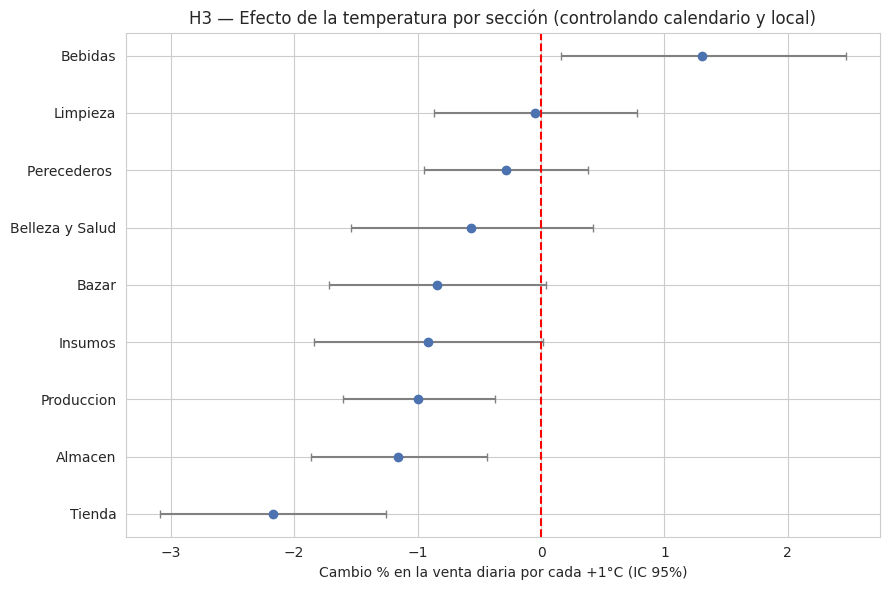

In [60]:
# --- 4.4 Gráfico: efecto de +1°C por sección (con IC 95%) ---
t = tabla_h3.sort_values('efecto_%_por_°C')
fig, ax = plt.subplots(figsize=(9, 6))
ax.errorbar(t['efecto_%_por_°C'], range(len(t)),
            xerr=[t['efecto_%_por_°C'] - t['IC95_inf_%'], t['IC95_sup_%'] - t['efecto_%_por_°C']],
            fmt='o', color='#4C72B0', ecolor='gray', capsize=3)
ax.axvline(0, color='red', linestyle='--')
ax.set_yticks(range(len(t)))
ax.set_yticklabels(t['desc_secciones'])
ax.set_xlabel('Cambio % en la venta diaria por cada +1°C (IC 95%)')
ax.set_title('H3 — Efecto de la temperatura por sección (controlando calendario y local)')
plt.tight_layout()
plt.show()

In [61]:
# --- 4.5 ANOVA de dos vías complementario: grupo climático x sección (el método sugerido en el plan) ---
modelo_anova_h3 = smf.ols('log_cant ~ C(grupo_climatico) * C(desc_secciones)', data=panel_h3).fit()
anova_h3 = sm.stats.anova_lm(modelo_anova_h3, typ=2)
anova_h3['eta2_parcial'] = anova_h3['sum_sq'] / (anova_h3['sum_sq'] + anova_h3.loc['Residual', 'sum_sq'])
anova_h3.loc['Residual', 'eta2_parcial'] = np.nan
print("Nota: este ANOVA no controla calendario ni agrupa por fecha; es un respaldo, la inferencia principal es 4.2.")
anova_h3

Nota: este ANOVA no controla calendario ni agrupa por fecha; es un respaldo, la inferencia principal es 4.2.


,sum_sq,df,F,PR(>F),eta2_parcial
C(grupo_climatico),25.020685,2.0,36.307272,2.234778e-16,0.014802
C(desc_secciones),5193.826377,8.0,1884.177688,0.000000e+00,0.757214
C(grupo_climatico):C(desc_secciones),39.665754,16.0,7.194824,7.991717e-17,0.023265
Residual,1665.299605,4833.0,NaN,NaN,NaN


In [62]:
# --- 4.6 Sensibilidad a valores extremos ---
# En 'cantidad' hay registros de hasta ±40,500 (probables errores de carga); se repite el test sin |cantidad| > p99.9.
umbral = df_final['cantidad'].abs().quantile(0.999)
panel_h3_s = armar_panel(df_final, 'desc_secciones', secciones_h3, umbral_extremo=umbral)
m_s = ajustar(f'log_cant ~ temp_c * C(desc_secciones) + {ctrl}', panel_h3_s)
nom_s = list(m_s.params.index)
idx_s = [i for i, n in enumerate(nom_s) if ':' in n and 'temp_c' in n]
R_s = np.zeros((len(idx_s), len(nom_s)))
for fila, j in enumerate(idx_s):
    R_s[fila, j] = 1
w_s = m_s.wald_test(R_s, use_f=True, scalar=True)
f_s, p_s = float(w_s.statistic), float(w_s.pvalue)
print(f"Sin extremos (|cantidad| <= {umbral:.1f}): F = {f_s:.2f}, p = {p_s:.3g}")
print(f"Conclusión {'se mantiene' if (p_s < 0.05) == significativo_h3 else 'CAMBIA'} respecto del análisis principal.")

Celdas fecha x local x grupo: 4,860 | descartadas por venta diaria <= 0: 0
Sin extremos (|cantidad| <= 14.5): F = 51.25, p = 6.67e-50
Conclusión se mantiene respecto del análisis principal.


In [63]:
# --- 4.7 Exploratorio: sustitución dentro de 'Bebidas' (por subsección) ---
# Idea del plan original: bebidas frías vs. calientes. Se mira a nivel desc_sub_secciones.
# Es exploratorio (muchas subsecciones, sin hipótesis fijada de antemano): se reporta con corrección de Holm.
bebidas = df_final[df_final['desc_secciones'] == 'Bebidas']
conteo_sub = bebidas['desc_sub_secciones'].value_counts()
print(conteo_sub.head(15))

subs = conteo_sub[conteo_sub >= 20_000].index.tolist()
if len(subs) >= 2:
    panel_sub = armar_panel(bebidas, 'desc_sub_secciones', subs)
    tabla_sub = pendientes_por_grupo(panel_sub, 'desc_sub_secciones')
    display(tabla_sub.round(4))
else:
    print("Hay menos de 2 subsecciones con volumen suficiente; se omite este análisis.")

desc_sub_secciones
Sin Alcohol    355767
Con Alcohol     71922
Name: count, dtype: int64
Celdas fecha x local x grupo: 1,080 | descartadas por venta diaria <= 0: 0


,desc_sub_secciones,n_obs,coef,p_valor,efecto_%_por_°C,IC95_inf_%,IC95_sup_%,p_holm,signif_holm
0,Sin Alcohol,540,0.0120,0.0016,1.2051,0.4552,1.9606,0.0032,True
1,Con Alcohol,540,0.0114,0.3052,1.1428,-1.0305,3.3639,0.3052,False


In [64]:
# --- 4.8 Conclusión -- H3 ---
n_pos = int(((tabla_h3['efecto_%_por_°C'] > 0) & tabla_h3['signif_holm']).sum())
n_neg = int(((tabla_h3['efecto_%_por_°C'] < 0) & tabla_h3['signif_holm']).sum())
mayor = tabla_h3.iloc[0]
menor = tabla_h3.iloc[-1]

display(Markdown(f'''
### Conclusión -- H3

{"Se rechaza" if significativo_h3 else "No se rechaza"} la hipótesis nula de pendiente común (Wald F = {f_h3:.2f}, p = {p_h3:.3g}; agrupado por fecha).
La interacción temperatura × sección aporta un R² parcial de **{r2_parcial_h3:.4f}**.

Secciones con efecto significativo tras la corrección de Holm: **{n_pos}** positivo(s) y **{n_neg}** negativo(s).
Mayor efecto positivo: **{mayor["desc_secciones"]}** ({mayor["efecto_%_por_°C"]:+.2f}% por °C, IC95 [{mayor["IC95_inf_%"]:.2f}; {mayor["IC95_sup_%"]:.2f}]).
Mayor efecto negativo: **{menor["desc_secciones"]}** ({menor["efecto_%_por_°C"]:+.2f}% por °C, IC95 [{menor["IC95_inf_%"]:.2f}; {menor["IC95_sup_%"]:.2f}]).
{"Hay secciones con signos opuestos, patrón compatible con sustitución entre categorías." if (n_pos > 0 and n_neg > 0) else "No hay secciones con signos opuestos y significativos, por lo que la evidencia de sustitución es débil."}

**Sensibilidad:** sin valores extremos, el test de interacción da p = {p_s:.3g}; la conclusión {"se mantiene" if (p_s < 0.05) == significativo_h3 else "cambia"}.

**Limitaciones:** (i) 1 solo año parcial (enero-septiembre 2021), igual que en H2; (ii) con el control por mes, el efecto de la temperatura se identifica por las variaciones día a día dentro de cada mes, no por la estacionalidad (ver columna *sin_control_mes*); (iii) 2 locales y dos estaciones meteorológicas, es decir poca variación climática independiente.
'''))


### Conclusión -- H3

Se rechaza la hipótesis nula de pendiente común (Wald F = 50.26, p = 3.17e-49; agrupado por fecha).
La interacción temperatura × sección aporta un R² parcial de **0.0417**.

Secciones con efecto significativo tras la corrección de Holm: **0** positivo(s) y **3** negativo(s).
Mayor efecto positivo: **Bebidas** (+1.31% por °C, IC95 [0.16; 2.47]).
Mayor efecto negativo: **Tienda** (-2.17% por °C, IC95 [-3.09; -1.25]).
No hay secciones con signos opuestos y significativos, por lo que la evidencia de sustitución es débil.

**Sensibilidad:** sin valores extremos, el test de interacción da p = 6.67e-50; la conclusión se mantiene.

**Limitaciones:** (i) 1 solo año parcial (enero-septiembre 2021), igual que en H2; (ii) con el control por mes, el efecto de la temperatura se identifica por las variaciones día a día dentro de cada mes, no por la estacionalidad (ver columna *sin_control_mes*); (iii) 2 locales y dos estaciones meteorológicas, es decir poca variación climática independiente.


# 5. H4 — El fin de semana modera el efecto climático

**H0 (nula):** el coeficiente de la interacción `temperatura × es_fin_de_semana` es igual a 0 (la pendiente de la temperatura es la misma en días hábiles y fines de semana).

**H1 (alternativa):** el coeficiente de la interacción es distinto de 0 (el fin de semana amplifica o atenúa el efecto climático).

**Nivel de significancia:** α = 0.05

**Método:** extensión del modelo de H2 con el término de interacción: `cantidad_total ~ temp_c * es_fin_de_semana + es_feriado + C(mes)`, sobre la serie diaria. La temperatura se **centra** (`temp_c`) para que el coeficiente de `es_fin_de_semana` se lea a la temperatura media y no a 0°C, lo cual no tendría sentido.

In [65]:
# --- 5.1 Serie diaria y modelo con interacción ---
agg_h4 = df_final.groupby('fecha_vta', observed=True).agg(
    cantidad_total=('cantidad', 'sum'),
    temperatura_promedio=('temperatura', 'mean'),
    mes=('mes', 'first'),
    es_fin_de_semana=('es_fin_de_semana', 'first'),
    es_feriado=('es_feriado', 'first'),
).reset_index()
agg_h4['es_fin_de_semana'] = agg_h4['es_fin_de_semana'].astype(int)
agg_h4['es_feriado'] = agg_h4['es_feriado'].astype(int)
agg_h4['temp_c'] = agg_h4['temperatura_promedio'] - agg_h4['temperatura_promedio'].mean()

print(f"Observaciones (días): {len(agg_h4)} | fines de semana: {agg_h4['es_fin_de_semana'].sum()} | hábiles: {(agg_h4['es_fin_de_semana'] == 0).sum()}")

formula_h4 = 'cantidad_total ~ temp_c * es_fin_de_semana + es_feriado + C(mes)'
modelo_h4 = smf.ols(formula_h4, data=agg_h4).fit()
modelo_h4_hc3 = smf.ols(formula_h4, data=agg_h4).fit(cov_type='HC3')

def nombre_interaccion(modelo):
    '''Busca en los coeficientes del modelo el término temp_c x es_fin_de_semana (patsy puede invertir el orden).'''
    cand = [n for n in modelo.params.index if ':' in str(n) and 'temp_c' in str(n) and 'es_fin_de_semana' in str(n)]
    if not cand:
        raise KeyError(f"No se encontró la interacción. Coeficientes disponibles: {list(modelo.params.index)}")
    return cand[0]

term = nombre_interaccion(modelo_h4)
print('Término de interacción detectado:', term)
ci_hc3 = modelo_h4_hc3.conf_int()
ci_cl = modelo_h4.conf_int()
resumen_h4 = pd.DataFrame({
    'coef': [modelo_h4.params[term]] * 2,
    'p_valor': [modelo_h4.pvalues[term], modelo_h4_hc3.pvalues[term]],
    'IC95_inf': [np.asarray(ci_cl.loc[term])[0], np.asarray(ci_hc3.loc[term])[0]],
    'IC95_sup': [np.asarray(ci_cl.loc[term])[1], np.asarray(ci_hc3.loc[term])[1]],
}, index=['MCO clásico', 'HC3 (robusto)'])
print(f"R² ajustado: {modelo_h4.rsquared_adj:.3f}")
resumen_h4.round(4)

Observaciones (días): 271 | fines de semana: 78 | hábiles: 193
Término de interacción detectado: temp_c:es_fin_de_semana
R² ajustado: 0.583


,coef,p_valor,IC95_inf,IC95_sup
MCO clásico,25.2759,0.8992,-367.1978,417.7496
HC3 (robusto),25.2759,0.9105,-415.6265,466.1784


In [66]:
# --- 5.2 Pendientes simples: efecto de +1°C en día hábil vs. fin de semana ---
t_habil = modelo_h4_hc3.t_test('temp_c = 0')
contraste = np.zeros(len(modelo_h4_hc3.params))
contraste[list(modelo_h4_hc3.params.index).index('temp_c')] = 1
contraste[list(modelo_h4_hc3.params.index).index(term)] = 1
t_finde = modelo_h4_hc3.t_test(contraste)   # pendiente en fin de semana = temp_c + interacción

def fila(nombre, t):
    lo, hi = np.asarray(t.conf_int()).ravel()[:2]
    return {'día': nombre, 'unidades_por_°C': float(t.effect[0]), 'IC95_inf': lo, 'IC95_sup': hi, 'p_valor': float(t.pvalue)}

pendientes_h4 = pd.DataFrame([fila('Día hábil', t_habil), fila('Fin de semana', t_finde)]).set_index('día')
pendientes_h4.round(4)

,unidades_por_°C,IC95_inf,IC95_sup,p_valor
día,,,,
Día hábil,-136.8161,-353.7528,80.1206,0.2164
Fin de semana,-111.5402,-563.3239,340.2435,0.6285


In [67]:
# --- 5.3 Verificación de supuestos ---
res_h4 = modelo_h4.resid
shapiro_h4 = stats.shapiro(res_h4)
bp_h4 = het_breuschpagan(res_h4, modelo_h4.model.exog)
print(f"Shapiro-Wilk: estadístico={shapiro_h4[0]:.4f}, p={shapiro_h4[1]:.5f}")
print(f"Breusch-Pagan: estadístico={bp_h4[0]:.4f}, p={bp_h4[1]:.5f}")

# VIF con temperatura centrada (sin centrar, la interacción se infla artificialmente)
X_vif = agg_h4[['temp_c', 'es_fin_de_semana', 'es_feriado']].copy()
X_vif['temp_x_finde'] = X_vif['temp_c'] * X_vif['es_fin_de_semana']
X_vif = sm.add_constant(X_vif)
pd.DataFrame({'variable': X_vif.columns,
              'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})

Shapiro-Wilk: estadístico=0.8707, p=0.00000
Breusch-Pagan: estadístico=20.0549, p=0.06605


,variable,VIF
0,const,1.000000
1,temp_c,1.341198
2,es_fin_de_semana,1.023148
3,es_feriado,1.021490
4,temp_x_finde,1.356742


In [68]:
# --- 5.4 Robustez: ¿la conclusión depende de la escala o del nivel de agregación? ---
# (a) En logaritmos: si el fin de semana multiplica las ventas, una interacción en unidades puede ser solo un efecto de escala.
m_log = smf.ols('np.log(cantidad_total) ~ temp_c * es_fin_de_semana + es_feriado + C(mes)',
                data=agg_h4).fit(cov_type='HC3')
term_log = nombre_interaccion(m_log)
p_log = float(m_log.pvalues[term_log])
print(f"(a) Modelo en log: interacción = {m_log.params[term_log]:.4f}, p = {p_log:.4f}")

# (b) Nivel local x día: la temperatura varía también entre locales (estaciones distintas) -> más variación climática.
panel_ld = cal_dia_local.merge(
    df_final.groupby(['fecha_vta', 'local'], observed=True)['cantidad'].sum().rename('cantidad_total').reset_index()
            .assign(local=lambda d: d['local'].astype(str)),
    on=['fecha_vta', 'local'])
panel_ld['temp_c'] = panel_ld['temperatura'] - panel_ld['temperatura'].mean()
m_ld = ajustar('cantidad_total ~ temp_c * es_fin_de_semana + es_feriado + C(mes) + C(local)', panel_ld)
term_ld = nombre_interaccion(m_ld)
p_ld = float(m_ld.pvalues[term_ld])
print(f"(b) Local x día (n={len(panel_ld)}, agrupado por fecha): interacción = {m_ld.params[term_ld]:.2f}, p = {p_ld:.4f}")

(a) Modelo en log: interacción = 0.0013, p = 0.8170
(b) Local x día (n=540, agrupado por fecha): interacción = 155.63, p = 0.1076


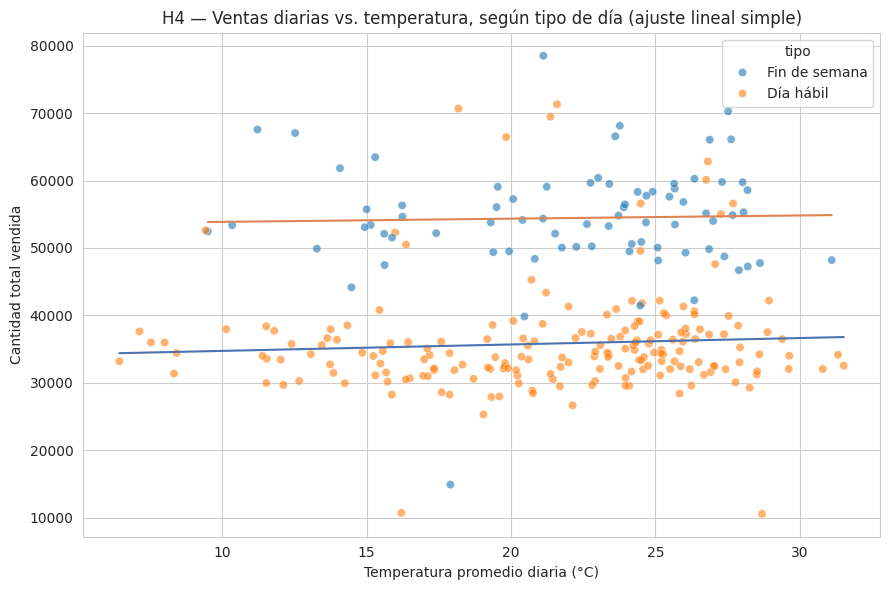

In [69]:
# --- 5.5 Gráfico de apoyo ---
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=agg_h4.assign(tipo=agg_h4['es_fin_de_semana'].map({0: 'Día hábil', 1: 'Fin de semana'})),
                x='temperatura_promedio', y='cantidad_total', hue='tipo', alpha=0.6, ax=ax)
for valor, color in [(0, '#4C72B0'), (1, '#DD8452')]:
    d = agg_h4[agg_h4['es_fin_de_semana'] == valor]
    pend, ord_ = np.polyfit(d['temperatura_promedio'], d['cantidad_total'], 1)
    xs = np.linspace(d['temperatura_promedio'].min(), d['temperatura_promedio'].max(), 50)
    ax.plot(xs, pend * xs + ord_, color=color)
ax.set_title('H4 — Ventas diarias vs. temperatura, según tipo de día (ajuste lineal simple)')
ax.set_xlabel('Temperatura promedio diaria (°C)')
ax.set_ylabel('Cantidad total vendida')
plt.tight_layout()
plt.show()

In [70]:
# --- 5.6 Conclusión -- H4 ---
p_h4 = modelo_h4_hc3.pvalues[term]
coef_h4 = modelo_h4.params[term]
signif_h4 = p_h4 < 0.05
hab, fin = pendientes_h4.loc['Día hábil'], pendientes_h4.loc['Fin de semana']
ic_h4 = np.asarray(modelo_h4_hc3.conf_int().loc[term])
coinciden = (modelo_h4.pvalues[term] < 0.05) == signif_h4

display(Markdown(f'''
### Conclusión -- H4

{"Se rechaza" if signif_h4 else "No se rechaza"} la hipótesis nula (p = {p_h4:.4f} con errores HC3; MCO clásico: p = {modelo_h4.pvalues[term]:.4f}{"" if coinciden else ", **discrepan**: tomar con cautela"}).
El coeficiente de interacción es **{coef_h4:.1f} unidades/°C** (IC95 [{ic_h4[0]:.1f}; {ic_h4[1]:.1f}]): por cada grado adicional, el fin de semana
{"suma" if coef_h4 > 0 else "resta"} {abs(coef_h4):.1f} unidades respecto de la pendiente de un día hábil.

Pendiente en día hábil: **{hab["unidades_por_°C"]:.1f}** unidades/°C (p = {hab["p_valor"]:.3f}). Pendiente en fin de semana: **{fin["unidades_por_°C"]:.1f}** unidades/°C (p = {fin["p_valor"]:.3f}).

**Robustez:** en logaritmos la interacción da p = {p_log:.4f}; a nivel local × día, p = {p_ld:.4f}.

**Supuestos:** Shapiro-Wilk p = {shapiro_h4[1]:.5f} {"(residuos no normales; con n=" + str(len(agg_h4)) + " se apoya en el TCL, como en H2)" if shapiro_h4[1] < 0.05 else ""}; Breusch-Pagan p = {bp_h4[1]:.4f} {"(heterocedasticidad: por eso la decisión se toma con HC3)" if bp_h4[1] < 0.05 else "(sin heterocedasticidad clara; HC3 se reporta igual por ser el caso límite en H2)"}.

**Potencia:** con 271 días (≈{int(agg_h4["es_fin_de_semana"].sum())} de fin de semana) un IC amplio indica que un efecto moderado podría no detectarse; no rechazar H0 no equivale a probar que no hay moderación.
**Limitación temporal:** igual que H2, solo enero-septiembre de 2021.
'''))


### Conclusión -- H4

No se rechaza la hipótesis nula (p = 0.9105 con errores HC3; MCO clásico: p = 0.8992).
El coeficiente de interacción es **25.3 unidades/°C** (IC95 [-415.6; 466.2]): por cada grado adicional, el fin de semana
suma 25.3 unidades respecto de la pendiente de un día hábil.

Pendiente en día hábil: **-136.8** unidades/°C (p = 0.216). Pendiente en fin de semana: **-111.5** unidades/°C (p = 0.628).

**Robustez:** en logaritmos la interacción da p = 0.8170; a nivel local × día, p = 0.1076.

**Supuestos:** Shapiro-Wilk p = 0.00000 (residuos no normales; con n=271 se apoya en el TCL, como en H2); Breusch-Pagan p = 0.0661 (sin heterocedasticidad clara; HC3 se reporta igual por ser el caso límite en H2).

**Potencia:** con 271 días (≈78 de fin de semana) un IC amplio indica que un efecto moderado podría no detectarse; no rechazar H0 no equivale a probar que no hay moderación.
**Limitación temporal:** igual que H2, solo enero-septiembre de 2021.
